# Week 12 Lab Work

**Dataset:** Adult / Census Income (UCI Machine Learning Repository)

1. Load the same pre-processed dataset as the last lab works.
2. Scale the features and build a Kohonen Self-Organizing Map (SOM) in numpy.
3. Train the SOM and measure the quantization error.
4. Show the U-matrix and the share of `>50K` rows on each node.
5. Read the map and write the conclusions.

In [1]:
import os
import urllib.request

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

cols = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]


def get_file(data_filename):
    for base in [".", ".."]:
        if not os.path.isdir(base):
            continue
        for root, dirs, files in os.walk(base):
            if data_filename in files:
                return os.path.join(root, data_filename)

    print(f"'{data_filename}' not found in the workspace. Downloading it dynamically...")
    url = f"https://archive.ics.uci.edu/ml/machine-learning-databases/adult/{data_filename}"
    urllib.request.urlretrieve(url, data_filename)
    return data_filename


# 1. Load and pre-process the data
path = get_file("adult.data")
print(f"Loading data from: {path}")
df = pd.read_csv(path, header=None, names=cols, skipinitialspace=True, na_values="?")
df = df.dropna().drop_duplicates().reset_index(drop=True)
df["income"] = (df["income"] == ">50K").astype(int)
df = pd.get_dummies(df, drop_first=True)

print("Shape:", df.shape)
print("Missing cells:", df.isnull().sum().sum())

Loading data from: ./adult.data
Shape: (30139, 97)
Missing cells: 0


## 2. Scale the features and build the SOM

`income` is kept out of the training features. It is used only later to color the map. `MinMaxScaler` puts every feature in the range 0 to 1, so no feature dominates the distance. `minisom` is not installed, so the SOM is written in numpy. A random subsample of 5000 rows is used to train, to keep it fast.

In [2]:
X = MinMaxScaler().fit_transform(df.drop(columns=["income"]))
y = df["income"].to_numpy()


def train_som(X, rows=10, cols=10, iters=20000, lr0=0.5, seed=42):
    rng = np.random.default_rng(seed)
    w = rng.random((rows, cols, X.shape[1]))
    gy, gx = np.mgrid[0:rows, 0:cols]
    sigma0 = max(rows, cols) / 2
    for t in range(iters):
        decay = np.exp(-t / iters)
        lr, sigma = lr0 * decay, sigma0 * decay
        x = X[rng.integers(len(X))]
        bmu = np.unravel_index(np.linalg.norm(w - x, axis=2).argmin(), (rows, cols))
        h = np.exp(-((gy - bmu[0]) ** 2 + (gx - bmu[1]) ** 2) / (2 * sigma ** 2))
        w += lr * h[..., None] * (x - w)
    return w


def bmus(w, X):
    d = np.linalg.norm(X[:, None, None, :] - w[None], axis=3).reshape(len(X), -1)
    return d.argmin(axis=1), d.min(axis=1)


idx = np.random.default_rng(42).choice(len(X), 5000, replace=False)
Xs, ys = X[idx], y[idx]
w = train_som(Xs)
print("Features:", X.shape[1], "| Map: 10 x 10 | Training rows:", len(Xs))

Features: 96 | Map: 10 x 10 | Training rows: 5000


## 3. Quantization error

In [3]:
bmu_s, dist_s = bmus(w, Xs)
bmu_all, dist_all = bmus(w, X)
print(f"Quantization error (training subsample): {dist_s.mean():.4f}")
print(f"Quantization error (all {len(X)} rows):    {dist_all.mean():.4f}")
print("Nodes with at least one row:", len(np.unique(bmu_all)), "of 100")

Quantization error (training subsample): 1.5701
Quantization error (all 30139 rows):    1.5659
Nodes with at least one row: 99 of 100


## 4. U-matrix and `>50K` share per node

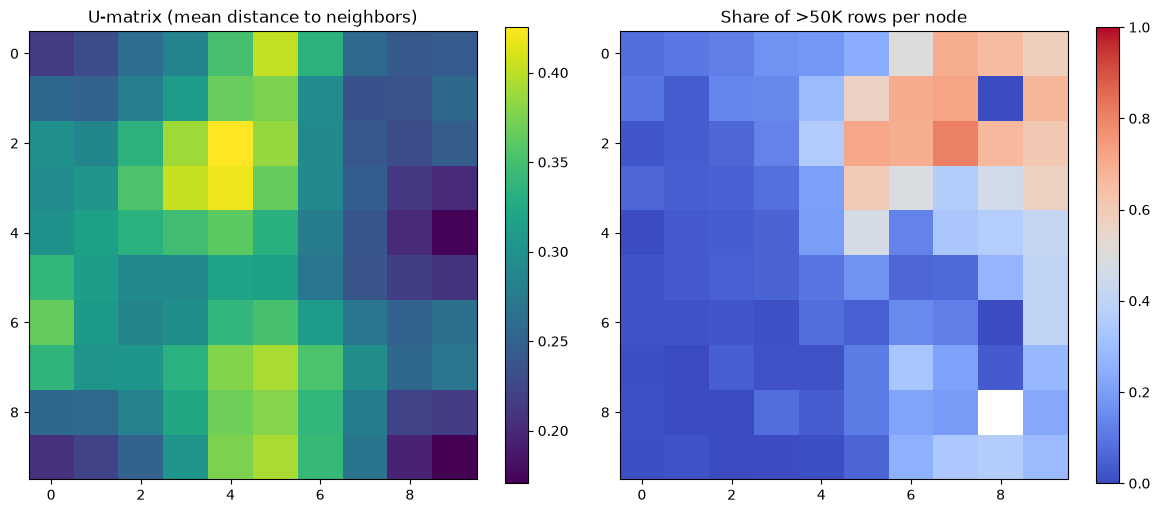

U-matrix: min 0.171, max 0.425, mean 0.295
Overall >50K share: 0.249
Node >50K share: min 0.000, max 0.805
Nodes with >50K share above 0.5: 14
Nodes with >50K share below 0.1: 44
Rows on nodes with share above 0.5: 5466 of 30139


In [4]:
R, C = w.shape[:2]
umat = np.zeros((R, C))
for i in range(R):
    for j in range(C):
        nb = [(i + a, j + b) for a, b in [(-1, 0), (1, 0), (0, -1), (0, 1)]
              if 0 <= i + a < R and 0 <= j + b < C]
        umat[i, j] = np.mean([np.linalg.norm(w[i, j] - w[p]) for p in nb])

hits = np.bincount(bmu_all, minlength=R * C)
pos = np.bincount(bmu_all, weights=y, minlength=R * C)
share = np.where(hits > 0, pos / np.maximum(hits, 1), np.nan).reshape(R, C)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
im = ax[0].imshow(umat, cmap="viridis")
ax[0].set_title("U-matrix (mean distance to neighbors)")
fig.colorbar(im, ax=ax[0])
im = ax[1].imshow(share, cmap="coolwarm", vmin=0, vmax=1)
ax[1].set_title("Share of >50K rows per node")
fig.colorbar(im, ax=ax[1])
plt.tight_layout()
plt.show()

print(f"U-matrix: min {umat.min():.3f}, max {umat.max():.3f}, mean {umat.mean():.3f}")
print(f"Overall >50K share: {y.mean():.3f}")
print(f"Node >50K share: min {np.nanmin(share):.3f}, max {np.nanmax(share):.3f}")
print("Nodes with >50K share above 0.5:", int((share > 0.5).sum()))
print("Nodes with >50K share below 0.1:", int((share < 0.1).sum()))
print(f"Rows on nodes with share above 0.5: {int(hits[(share > 0.5).ravel()].sum())} of {len(X)}")

## 5. Reading the map and conclusions

**Reading the map.** The U-matrix ranges from 0.171 to 0.425 (mean 0.295). A bright ridge of high values runs down the middle of the map (columns 4 and 5), so the SOM splits the data into a left group and a right group. The `>50K` map shows that 14 nodes have more than 50% `>50K` rows. They all sit in the top-right corner (rows 0 to 3, columns 5 to 9). 44 nodes have less than 10% `>50K` rows. The overall `>50K` share is 0.249.

- **Quantization error:** 1.5659 on all 30139 rows (1.5701 on the 5000-row training subsample). The two values are close, so the subsample was enough to train the map. The error is not small because the data has 96 features, most of them one-hot columns.
- **Clusters appear without labels:** the SOM was trained without `income`, yet the high-income rows gather in one corner (node share up to 0.805). So the features alone carry the income signal.
- **Not all clusters are pure:** the `>50K` share changes slowly across the map and 5466 of 30139 rows sit on nodes with share above 0.5. The classes overlap, so a SOM is good to explore the data but is not a classifier.
- **Use:** 99 of 100 nodes got at least one row, so the 10 x 10 map size fits this dataset.